# Session 8 — demand patterns, Phase 0 + Phase 1

Learner-led. For each question: **write your prediction first**, then do the analysis, then write
what you see and what it means. The goal is evidence for which Phase 2 candidates are worth building
(notes/phase2_strategy.md), not modelling.

Data: `data/processed/vn1_long_p0p1.parquet` — 183 weeks, 2020-07-06 → 2024-01-01.
D011 still applies: nothing from post-competition write-ups about Phase 2.

**Plotting note:** in the `vn1` env, `ax.plot` (line plots) works, but bar charts, histograms and
`savefig` crash the kernel (known matplotlib issue, PROGRESS.md Session 3). Use line plots or tables.

In [1]:
import os
from pathlib import Path

current = Path.cwd()
while not (current / "CONTEXT.md").is_file():
    if current == current.parent:
        raise FileNotFoundError("Could not find CONTEXT.md in any parent directory")
    current = current.parent
os.chdir(current)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import KEY
from src.features import classify_segment

df = pd.read_parquet("data/processed/vn1_long_p0p1.parquet")
PHASE1_START = pd.Timestamp("2023-10-09")
df["phase"] = np.where(df["date"] >= PHASE1_START, "phase1", "phase0")

# Wide views: one row per series, one column per week.
sales = df.pivot(index=KEY, columns="date", values="sales")
price = df.pivot(index=KEY, columns="date", values="price")
weekly_total = sales.sum()

# Segments from Phase 0 history only (Session 4 thresholds), for grouping.
segment = classify_segment((sales.loc[:, sales.columns < PHASE1_START] == 0).mean(axis=1))

print(sales.shape, sales.columns.min().date(), "->", sales.columns.max().date())
print(segment.value_counts().to_string())

(15053, 183) 2020-07-06 -> 2024-01-01
segment
intermittent    6896
sparse          6170
active          1987


**Available objects:** `df` (long), `sales` / `price` (wide: series × week), `weekly_total`
(portfolio total per week), `segment` (active / intermittent / sparse, by series), `KEY`.

Suggested first step for everything: plot `weekly_total` over all 183 weeks and look before
answering anything.

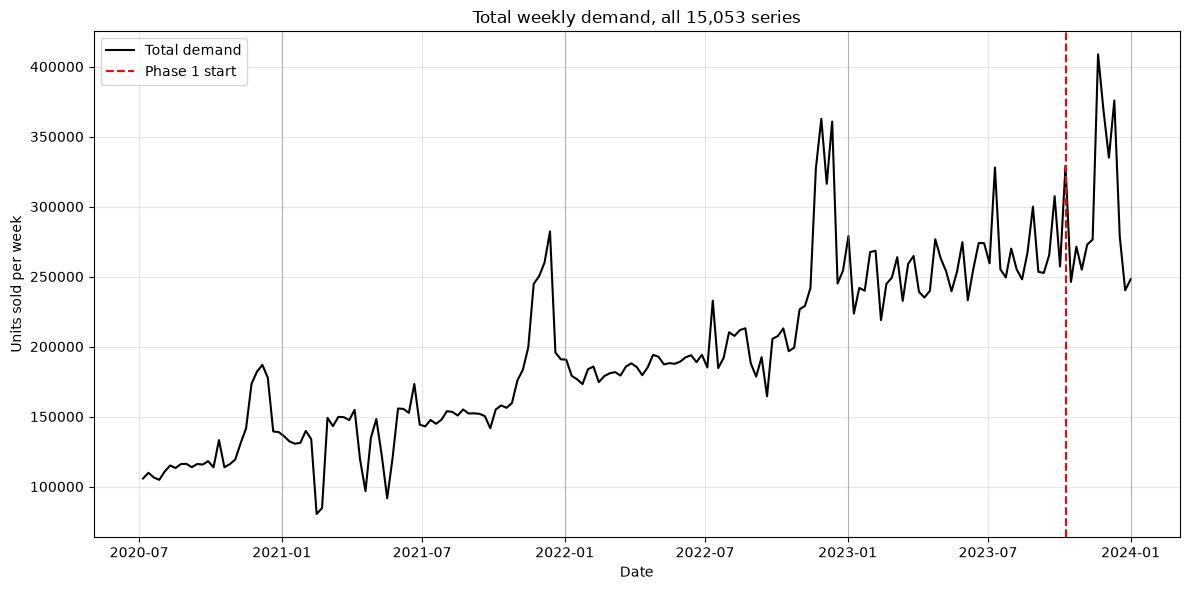

In [2]:
# Start here: look at total weekly demand over the whole history
# I expect to see a big drop in demand at the start of Phase 1, and then a slow recovery.
from pathlib import Path
Path("reports/figures").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(12, 6))
plt.plot(weekly_total.index, weekly_total.values, label="Total demand", color="black")

# Phase 1 start (the 13 weeks we forecast)
plt.axvline(PHASE1_START, color="red", linestyle="--", label="Phase 1 start")

# New Year markers, to compare the same time of year across years
for year in [2021, 2022, 2023, 2024]:
    plt.axvline(pd.Timestamp(f"{year}-01-01"), color="grey", linewidth=0.8, alpha=0.5)

plt.title("Total weekly demand, all 15,053 series")
plt.xlabel("Date")
plt.ylabel("Units sold per week")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("reports/figures/total_weekly_sales.png")
plt.show()


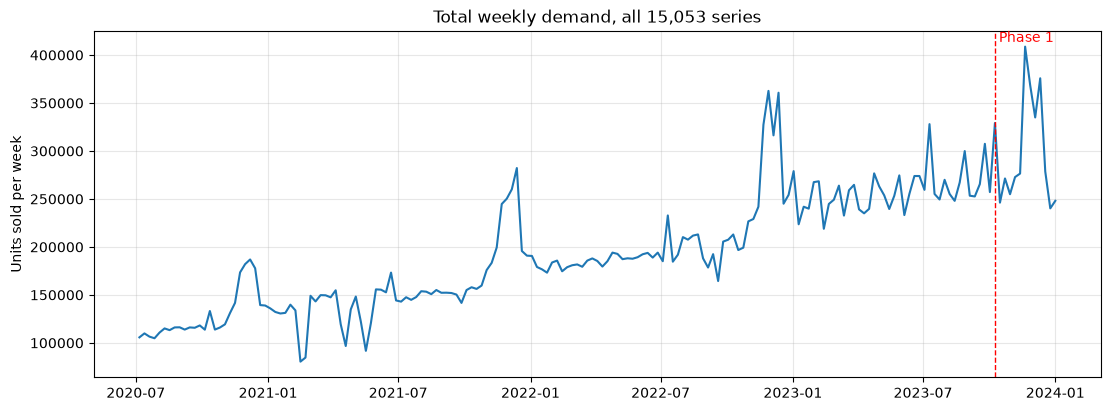

In [3]:
# Start here: look at total weekly demand over the whole history
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(weekly_total.index, weekly_total.values, linewidth=1.5)

# Mark where Phase 1 begins (the 13 weeks we forecast)
ax.axvline(PHASE1_START, color="red", linestyle="--", linewidth=1)
ax.text(PHASE1_START, ax.get_ylim()[1], " Phase 1", color="red", va="top")

ax.set_title("Total weekly demand, all 15,053 series")
ax.set_ylabel("Units sold per week")
ax.grid(alpha=0.3)
plt.show()


## 1. What drove the Q4 2023 peaks?

Which clients, warehouses and products drove the Nov 20 and Dec 11 peaks? What share of series carried most of the Q4 rise: a few, or many?

**My prediction (before looking):** 

**Why:** 

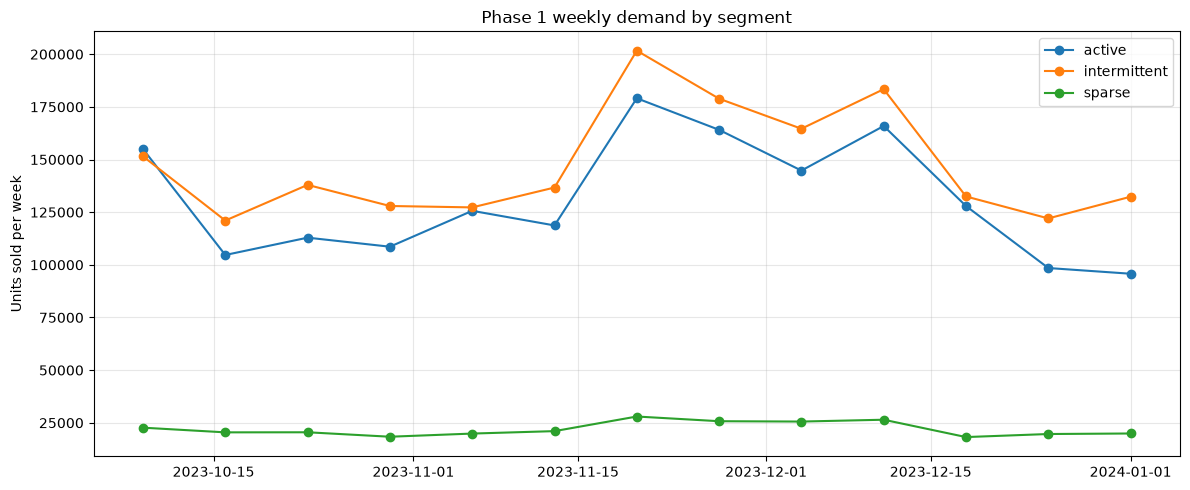

segment,active,intermittent,sparse
date,,,
2023-10-09,154946,151507,22684
2023-10-16,104671,121019,20461
2023-10-23,112899,137955,20497
2023-10-30,108606,127937,18385
2023-11-06,125642,127269,19884
2023-11-13,118702,136702,21044
2023-11-20,179079,201687,27980
2023-11-27,164084,178876,25753
2023-12-04,144749,164613,25589


In [4]:
# Q1a: which segment carried the Q4 2023 rise?
phase1_weeks = sales.columns[sales.columns >= PHASE1_START]
by_segment = sales[phase1_weeks].groupby(segment).sum().T   # rows = weeks, columns = segments

plt.figure(figsize=(12, 5))
for seg in ["active", "intermittent", "sparse"]:
    plt.plot(by_segment.index, by_segment[seg], marker="o", label=seg)
plt.title("Phase 1 weekly demand by segment")
plt.ylabel("Units sold per week")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

by_segment.round(0).astype(int)


Series with higher demand in peak weeks: 5,682 of 15,053
Total extra units per peak week: 155,825
Top 1% of all series (150) produce 49% of the rise
Top 5% of all series (752) produce 81% of the rise
Top 10% of all series (1,505) produce 92% of the rise
Top 20% of all series (3,010) produce 98% of the rise


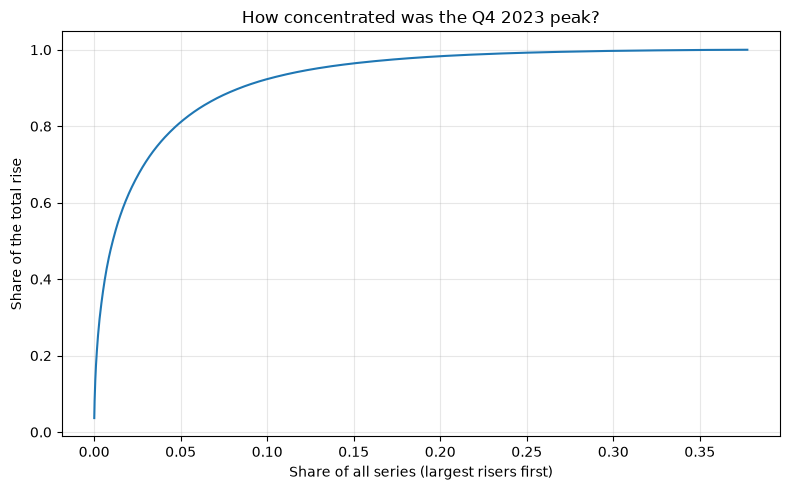

In [5]:
# Q1b: uplift per series = average of the two peak weeks minus a "normal" baseline
peak_weeks = [pd.Timestamp("2023-11-20"), pd.Timestamp("2023-12-11")]
baseline_weeks = phase1_weeks[:6]          # 2023-10-09 to 2023-11-13, before the peak

uplift = sales[peak_weeks].mean(axis=1) - sales[baseline_weeks].mean(axis=1)
positive = uplift[uplift > 0].sort_values(ascending=False)

print(f"Series with higher demand in peak weeks: {len(positive):,} of {len(uplift):,}")
print(f"Total extra units per peak week: {positive.sum():,.0f}")

# Cumulative share: what share of series produce what share of the rise?
cum_share = positive.cumsum() / positive.sum()
for pct in [0.01, 0.05, 0.10, 0.20]:
    n = int(len(uplift) * pct)
    print(f"Top {pct:.0%} of all series ({n:,}) produce {cum_share.iloc[n-1]:.0%} of the rise")

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cum_share) + 1) / len(uplift), cum_share.values)
plt.xlabel("Share of all series (largest risers first)")
plt.ylabel("Share of the total rise")
plt.title("How concentrated was the Q4 2023 peak?")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Q1c: where did the rise come from? # Which clients and warehouses?
uplift_df = uplift.rename("uplift").reset_index()
for level in ["Client", "Warehouse"]:
    top = uplift_df.groupby(level)["uplift"].sum().sort_values(ascending=False)
    share = top / top[top > 0].sum()
    print(f"\nTop 10 {level}s by uplift:")
    print(pd.DataFrame({"extra units": top.head(10).round(0), "share of rise": share.head(10).map("{:.1%}".format)}))


Top 10 Clients by uplift:
        extra units share of rise
Client                           
41          16531.0         13.2%
16          13582.0         10.9%
22          13370.0         10.7%
42          12622.0         10.1%
5           11906.0          9.5%
18          10642.0          8.5%
6            9342.0          7.5%
2            9242.0          7.4%
26           6767.0          5.4%
32           3918.0          3.1%

Top 10 Warehouses by uplift:
           extra units share of rise
Warehouse                           
265            11855.0          8.9%
67              9421.0          7.0%
251             9242.0          6.9%
177             6655.0          5.0%
228             6092.0          4.6%
99              4828.0          3.6%
10              4133.0          3.1%
33              3285.0          2.5%
90              2892.0          2.2%
58              2859.0          2.1%


 4: Which products?

In [7]:
# Q1d: top 15 individual series by uplift, with their segment
top_series = positive.head(15).rename("uplift").to_frame()
top_series["segment"] = segment.reindex(top_series.index)
top_series["baseline per week"] = sales.loc[top_series.index, baseline_weeks].mean(axis=1).round(0)
top_series["peak per week"] = sales.loc[top_series.index, peak_weeks].mean(axis=1).round(0)
top_series.round(0)

uplift       segment  baseline per week  \
Client Warehouse Product                                            
41     228       2866     5700.0        active             4113.0   
22     265       6181     3426.0        active             1102.0   
16     99        1103     1945.0        active              136.0   
                 2689     1693.0        active               95.0   
22     265       2184     1646.0  intermittent              330.0   
18     177       10918    1443.0        active              235.0   
16     305       3605     1390.0        active              269.0   
42     153       7079     1377.0  intermittent             1556.0   
26     74        4513     1372.0  intermittent             1540.0   
32     193       7056     1259.0  intermittent              588.0   
2      251       2723     1193.0  intermittent              718.0   
18     177       8535     1068.0        active              246.0   
41     330       9616      980.0        active               70.0   
       2         9410      977.0        active             1444.0   
                 1222      923.0        active             1675.0   

                          peak per week  
Client Warehouse Product                 
41     228       2866            9813.0  
22     265       6181            4528.0  
16     99        1103            2081.0  
                 2689            1788.0  
22     265       2184            1976.0  
18     177       10918           1678.0  
16     305       3605            1660.0  
42     153       7079            2934.0  
26     74        4513            2912.0  
32     193       7056            1848.0  
2      251       2723            1911.0  
18     177       8535            1314.0  
41     330       9616            1050.0  
       2         9410            2422.0  
                 1222            2598.0

**What I see:** 

**What it means for Phase 2:** 

## 2. What happens in January–April?

What did demand do in Jan–Apr 2021, 2022 and 2023, in total and by segment? Rising, falling or flat after the holidays? (This is the Phase 2 horizon.)

**My prediction (before looking):** 

**Why:** 

In [8]:
# Q2a: for each year, mirror the Phase 2 setup:
# origin = first Monday of January; forecast window = the next 13 weeks
weeks = sales.columns
def window_after(origin, n=13):
    i = weeks.get_loc(origin)
    return weeks[i + 1 : i + 1 + n]

def window_before(origin, n):
    i = weeks.get_loc(origin)
    return weeks[max(0, i - n + 1) : i + 1]       # includes the origin week

origins = {y: weeks[weeks >= pd.Timestamp(f"{y}-01-01")][0] for y in [2021, 2022, 2023, 2024]}
for y, o in origins.items():
    w = window_after(o)
    print(y, "origin", o.date(), "| Jan-Apr window:",
          f"{w[0].date()} -> {w[-1].date()}" if len(w) else "(Phase 2: no data yet)")

2021 origin 2021-01-04 | Jan-Apr window: 2021-01-11 -> 2021-04-05
2022 origin 2022-01-03 | Jan-Apr window: 2022-01-10 -> 2022-04-04
2023 origin 2023-01-02 | Jan-Apr window: 2023-01-09 -> 2023-04-03
2024 origin 2024-01-01 | Jan-Apr window: (Phase 2: no data yet)


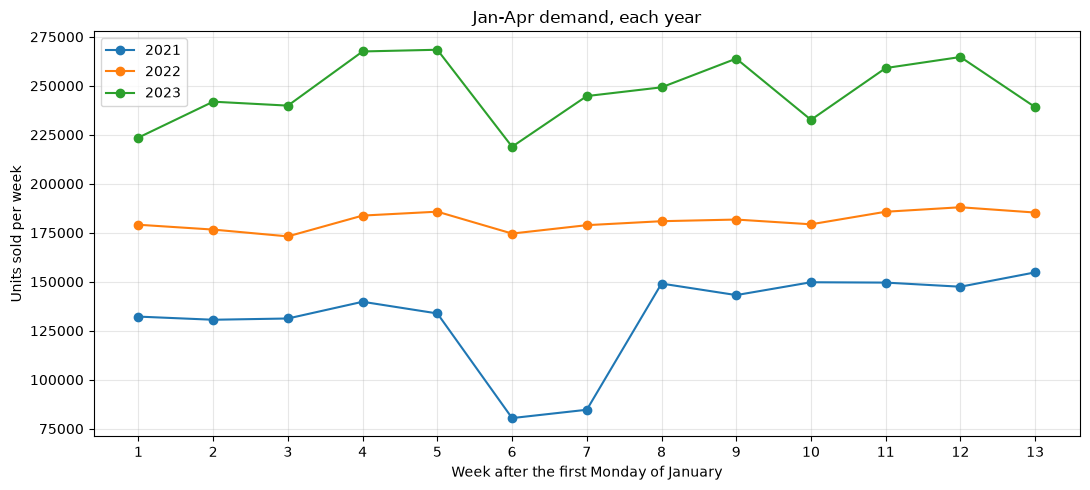

In [9]:
# Q2b: weekly Jan-Apr demand for 2021, 2022, 2023 on the same axis (week 1..13)
plt.figure(figsize=(11, 5))
for y in [2021, 2022, 2023]:
    w = window_after(origins[y])
    plt.plot(range(1, 14), weekly_total[w].values, marker="o", label=str(y))
plt.xticks(range(1, 14))
plt.xlabel("Week after the first Monday of January")
plt.ylabel("Units sold per week")
plt.title("Jan-Apr demand, each year")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# Q2c: compare each Jan-Apr with (a) the Q4 just before it and
# (b) the last 4 weeks before the origin (exactly what MA4 would use)
rows = []
for y in [2021, 2022, 2023]:
    o = origins[y]
    jan_apr = weekly_total[window_after(o)].mean()
    q4 = weekly_total[window_before(o, 13)].mean()
    last4 = weekly_total[window_before(o, 4)].mean()
    rows.append({
        "year": y,
        "Jan-Apr avg/week": round(jan_apr),
        "previous 13 wks avg/week": round(q4),
        "last 4 wks avg/week (MA4)": round(last4),
        "Jan-Apr vs previous 13 wks": f"{jan_apr / q4 - 1:+.1%}",
        "Jan-Apr vs last 4 wks": f"{jan_apr / last4 - 1:+.1%}",
    })
pd.DataFrame(rows).set_index("year")

,Jan-Apr avg/week,previous 13 wks avg/week,last 4 wks avg/week (MA4),Jan-Apr vs previous 13 wks,Jan-Apr vs last 4 wks
year,,,,,
2021,132816,145332,147986,-8.6%,-10.3%
2022,180992,203618,214858,-11.1%,-15.8%
2023,247196,265520,284740,-6.9%,-13.2%


**What I see:** 

**What it means for Phase 2:** 

In [11]:
# Q2d: does the post-holiday change differ across active / intermittent / sparse?
seg_total = sales.groupby(segment).sum()          # rows = segments, columns = weeks
rows = []
for y in [2021, 2022, 2023]:
    o = origins[y]
    for seg in ["active", "intermittent", "sparse"]:
        jan_apr = seg_total.loc[seg, window_after(o)].mean()
        q4 = seg_total.loc[seg, window_before(o, 13)].mean()
        last4 = seg_total.loc[seg, window_before(o, 4)].mean()
        rows.append({"year": y, "segment": seg,
                     "vs previous 13 wks": jan_apr / q4 - 1,
                     "vs last 4 wks (MA4)": jan_apr / last4 - 1})
seg_table = pd.DataFrame(rows).pivot(index="segment", columns="year")
seg_table.map("{:+.1%}".format)

vs previous 13 wks                 vs last 4 wks (MA4)          \
year                       2021    2022    2023                2021    2022   
segment                                                                       
active                    -5.1%  -12.0%  -14.4%               -7.7%  -14.5%   
intermittent             -32.6%   -7.9%   +2.5%              -28.2%  -19.2%   
sparse                   -42.7%  -47.8%  +67.0%              -58.5%  -50.3%   

                       
year             2023  
segment                
active         -18.6%  
intermittent    -7.7%  
sparse        +207.5%

## 3. Why was the 2023 rise weaker?

Q4 2023 rose 11%; 2020–2022 rose 26–37%. Is the difference visible in a few series or in all of them?

**My prediction (before looking):** 

**Why:** 

In [12]:
# Q3a: Q4 rise per year, with the same setup as Phase 1:
# origin = first Monday of October; compare the 13 weeks before vs the 13 weeks after
weeks = sales.columns
def window_after(origin, n=13):
    i = weeks.get_loc(origin)
    return weeks[i + 1 : i + 1 + n]

def window_before(origin, n=13):
    i = weeks.get_loc(origin)
    return weeks[max(0, i - n + 1) : i + 1]

q4_origins = {y: weeks[weeks >= pd.Timestamp(f"{y}-10-01")][0] for y in [2020, 2021, 2022, 2023]}

rows = []
for y, o in q4_origins.items():
    before = weekly_total[window_before(o)].mean()
    q4 = weekly_total[window_after(o)].mean()
    rows.append({"year": y, "origin": o.date(),
                 "Jul-Sep avg/week": round(before), "Oct-Dec avg/week": round(q4),
                 "Q4 rise": q4 / before - 1})
q4_table = pd.DataFrame(rows).set_index("year")

# Year-on-year: did the summer get stronger, or did Q4 get weaker?
q4_table["Jul-Sep vs last year"] = q4_table["Jul-Sep avg/week"].pct_change()
q4_table["Oct-Dec vs last year"] = q4_table["Oct-Dec avg/week"].pct_change()
q4_table.style.format({"Q4 rise": "{:+.1%}", "Jul-Sep vs last year": "{:+.1%}",
                       "Oct-Dec vs last year": "{:+.1%}"})


,origin,Jul-Sep avg/week,Oct-Dec avg/week,Q4 rise,Jul-Sep vs last year,Oct-Dec vs last year
year,,,,,,
2020,2020-10-05,113079,145332,+28.5%,+nan%,+nan%
2021,2021-10-04,150504,203618,+35.3%,+33.1%,+40.1%
2022,2022-10-03,199113,265520,+33.4%,+32.3%,+30.4%
2023,2023-10-02,269910,300447,+11.3%,+35.6%,+13.2%


In [13]:
# Q3b: did all segments rise less in 2023, or only some?
seg_total = sales.groupby(segment).sum()          # rows = segments, columns = weeks
rows = []
for y, o in q4_origins.items():
    for seg in ["active", "intermittent", "sparse"]:
        before = seg_total.loc[seg, window_before(o)].mean()
        q4 = seg_total.loc[seg, window_after(o)].mean()
        rows.append({"year": y, "segment": seg, "Q4 rise": q4 / before - 1})
pd.DataFrame(rows).pivot(index="segment", columns="year", values="Q4 rise").map("{:+.1%}".format)

year,2020,2021,2022,2023
segment,,,,
active,+23.8%,+20.2%,+10.0%,+4.2%
intermittent,+74.1%,+129.6%,+87.9%,+14.3%
sparse,+149.9%,+37.7%,+279.1%,+44.1%


In [14]:
#Your prediction first: do you expect the same products to be the big Q4 risers in both 2022 and 2023, or mostly different ones? Write it before running.
#Answer: I expect mostly different products to be the big Q4 risers in 2022 and 2023, as market conditions, consumer preferences, and product availability can change from year to year.
# Q3c: compare 2022 and 2023 series by series
def series_uplift(y):
    o = q4_origins[y]
    return sales[window_after(o)].mean(axis=1) - sales[window_before(o)].mean(axis=1)

up22, up23 = series_uplift(2022), series_uplift(2023)
print(f"Series that rose in Q4: 2022 {(up22 > 0).mean():.1%}   2023 {(up23 > 0).mean():.1%}")
print(f"Total uplift per week:  2022 {up22[up22 > 0].sum():,.0f}   2023 {up23[up23 > 0].sum():,.0f}")

top_n = 750   # about the top 5% of series
top22 = up22.nlargest(top_n).index
top23 = up23.nlargest(top_n).index
overlap = len(top22.intersection(top23))
print(f"\nOf the top {top_n} risers in 2023, {overlap} ({overlap / top_n:.0%}) were also top {top_n} risers in 2022")

print(f"\n2022's top {top_n} risers: uplift {up22[top22].sum():,.0f} in 2022 -> {up23[top22].sum():,.0f} in 2023")
rest = up22.index.difference(top22)
print(f"All other series:        uplift {up22[rest].sum():,.0f} in 2022 -> {up23[rest].sum():,.0f} in 2023")

Series that rose in Q4: 2022 37.2%   2023 38.6%
Total uplift per week:  2022 99,400   2023 75,376

Of the top 750 risers in 2023, 340 (45%) were also top 750 risers in 2022

2022's top 750 risers: uplift 79,685 in 2022 -> 23,679 in 2023
All other series:        uplift -13,278 in 2022 -> 6,858 in 2023


**What I see:** 

**What it means for Phase 2:** 

In [15]:
#Q3 cell 4: where did the "missing" rise go?

# Q3d: change in uplift (2023 minus 2022), in units per week, by segment
summary = pd.DataFrame({
    "uplift 2022": up22.groupby(segment).sum(),
    "uplift 2023": up23.groupby(segment).sum(),
})
summary["change"] = summary["uplift 2023"] - summary["uplift 2022"]
summary.round(0).astype(int)

,uplift 2022,uplift 2023,change
segment,,,
active,14061,5283,-8778
intermittent,51019,18512,-32507
sparse,1327,6741,5415


## 4. Spikes

How often do series have isolated weeks far above their usual level? Do those weeks cluster in particular weeks of the year?

**My prediction (before looking):** 

**Why:** 

In [16]:
# Q4a: find isolated spike weeks in every series
def find_spikes(sales, k=5, min_units=20, neighbour_k=2):
    vals = sales.to_numpy(dtype=float)
    nz = np.where(vals > 0, vals, np.nan)
    usual = np.nanmedian(nz, axis=1, keepdims=True)          # median of non-zero weeks
    usual = np.nan_to_num(usual, nan=0.0)
    prev = np.pad(vals[:, :-1], ((0, 0), (1, 0)))             # previous week (0 before start)
    nxt = np.pad(vals[:, 1:], ((0, 0), (0, 1)))               # next week (0 after end)
    is_spike = ((vals >= k * usual) & (vals >= min_units)
                & (prev < neighbour_k * usual) & (nxt < neighbour_k * usual))
    return pd.DataFrame(is_spike, index=sales.index, columns=sales.columns)

spikes = find_spikes(sales)
n_series_with_spike = spikes.any(axis=1).sum()
spike_units = sales.where(spikes, 0).to_numpy().sum()
print(f"Spike weeks found: {spikes.to_numpy().sum():,}")
print(f"Series with at least one spike: {n_series_with_spike:,} of {len(sales):,} ({n_series_with_spike / len(sales):.1%})")
print(f"Units sold in spike weeks: {spike_units:,.0f} = {spike_units / sales.to_numpy().sum():.1%} of all units")

Spike weeks found: 1,183
Series with at least one spike: 795 of 15,053 (5.3%)
Units sold in spike weeks: 343,747 = 0.9% of all units


In [17]:
# Q4b: which segments have spikes?
by_seg = pd.DataFrame({
    "series": segment.value_counts(),
    "series with a spike": spikes.any(axis=1).groupby(segment).sum(),
    "spike weeks": spikes.sum(axis=1).groupby(segment).sum(),
})
by_seg["share with a spike"] = (by_seg["series with a spike"] / by_seg["series"]).map("{:.1%}".format)
by_seg



,series,series with a spike,spike weeks,share with a spike
segment,,,,
active,1987,208,302,10.5%
intermittent,6896,486,761,7.0%
sparse,6170,101,120,1.6%


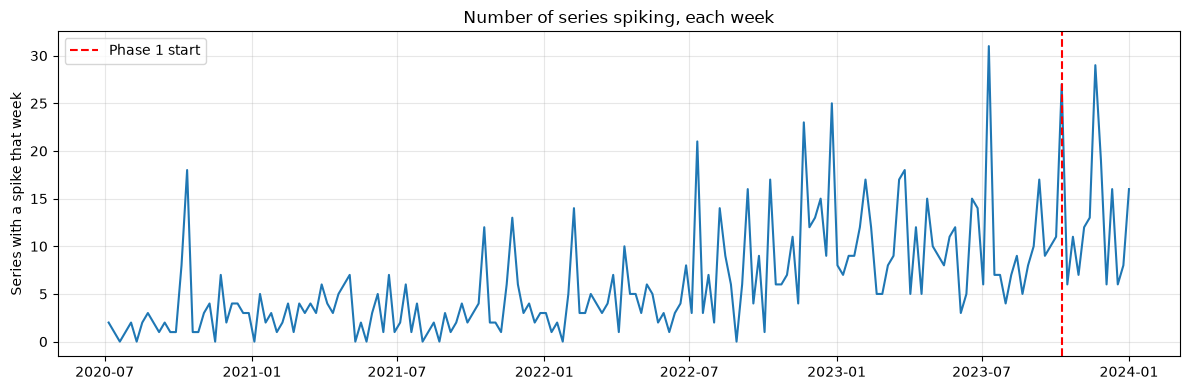

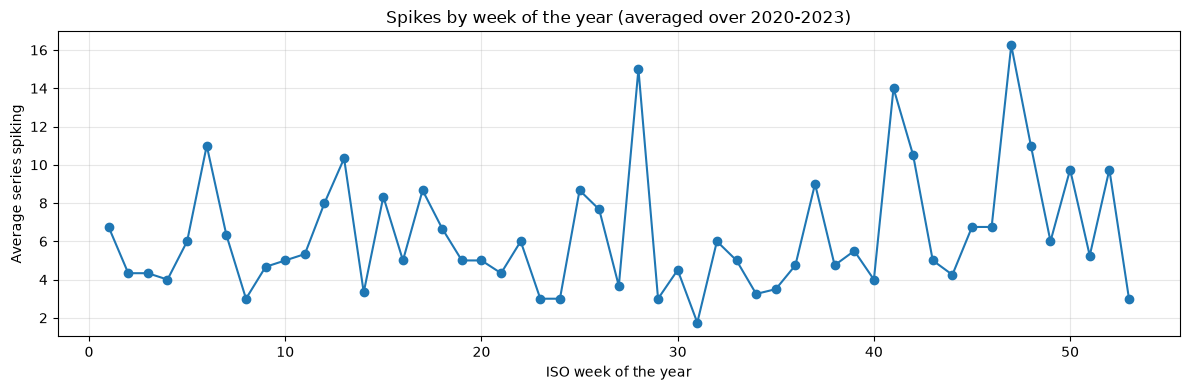

Weeks with the most spikes:
date
2023-07-10    31
2023-11-20    29
2023-10-09    27
2022-12-26    25
2022-11-21    23
2022-07-11    21
2023-11-27    19
2023-03-27    18
2020-10-12    18
2022-10-10    17
dtype: int64


In [18]:

# Q4c: spike counts by calendar week, and by week of the year
spikes_per_week = spikes.sum()                              # one value per calendar week
plt.figure(figsize=(12, 4))
plt.plot(spikes_per_week.index, spikes_per_week.values)
plt.axvline(PHASE1_START, color="red", linestyle="--", label="Phase 1 start")
plt.title("Number of series spiking, each week")
plt.ylabel("Series with a spike that week")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Fold the calendar onto week-of-year (1-53), averaging across years
woy = pd.Series(spikes_per_week.index.isocalendar().week.to_numpy(), index=spikes_per_week.index)
by_woy = spikes_per_week.groupby(woy).mean()
plt.figure(figsize=(12, 4))
plt.plot(by_woy.index, by_woy.values, marker="o")
plt.xlabel("ISO week of the year")
plt.ylabel("Average series spiking")
plt.title("Spikes by week of the year (averaged over 2020-2023)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Weeks with the most spikes:")
print(spikes_per_week.sort_values(ascending=False).head(10))

In [19]:
# Q4d: does the answer depend on the threshold?
for k in [3, 5, 10]:
    s = find_spikes(sales, k=k)
    share_series = s.any(axis=1).mean()
    share_units = sales.where(s, 0).to_numpy().sum() / sales.to_numpy().sum()
    print(f"k={k:>2}: {share_series:.1%} of series have a spike; spikes hold {share_units:.1%} of all units")

k= 3: 12.5% of series have a spike; spikes hold 1.8% of all units
k= 5: 5.3% of series have a spike; spikes hold 0.9% of all units


k=10: 2.0% of series have a spike; spikes hold 0.5% of all units


**What I see:** 

**What it means for Phase 2:** 

## 5. Late starters (pre-launch zeros)

How many series start selling partway through the history? Do they behave differently once active?

**My prediction (before looking):** 

**Why:** 

Selling in the very first week: 2,224 (14.8%)
First sale more than 3 months after data start: 11,325 (75.2%)
First sale more than 12 months after data start: 9,176 (61.0%)
First sale more than 24 months after data start: 5,730 (38.1%)

Series whose segment changes once pre-launch zeros are excluded: 6,074


after first sale,active,intermittent,sparse,All
label (all weeks),,,,
active,1987,0,0,1987
intermittent,2638,4258,0,6896
sparse,757,2679,2734,6170
All,5382,6937,2734,15053


First sold within the 52 weeks before the Phase 2 origin: 3,727 (24.8%), 15.7% of Phase 1 demand


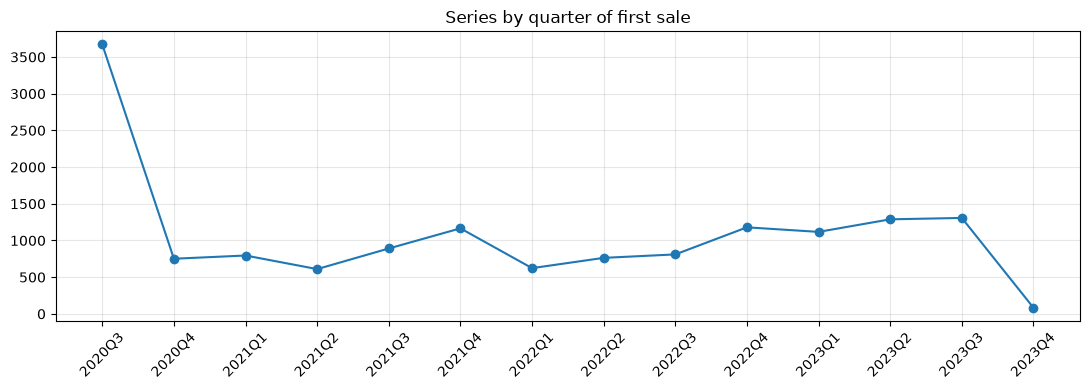

In [20]:
# Q5: late starters
vals = sales.to_numpy()
first_idx = (vals > 0).argmax(axis=1)                         # first week with a sale
first_sale = pd.Series(sales.columns[first_idx], index=sales.index)

print(f"Selling in the very first week: {(first_idx == 0).sum():,} ({(first_idx == 0).mean():.1%})")
for months in [3, 12, 24]:
    late = first_sale > sales.columns[0] + pd.DateOffset(months=months)
    print(f"First sale more than {months} months after data start: {late.sum():,} ({late.mean():.1%})")

# Segment label (all Phase 0 weeks) vs. segment counted only after the first sale
p0 = sales.loc[:, sales.columns < PHASE1_START].to_numpy()
alive = np.arange(p0.shape[1]) >= first_idx[:, None]
zero_rate_alive = ((p0 == 0) & alive).sum(axis=1) / alive.sum(axis=1)
segment_alive = classify_segment(pd.Series(zero_rate_alive, index=sales.index))
print()
print(f"Series whose segment changes once pre-launch zeros are excluded: {(segment != segment_alive).sum():,}")
display(pd.crosstab(segment.rename("label (all weeks)"), segment_alive.rename("after first sale"), margins=True))

# Series with less than a year of history at the Phase 2 origin
recent = first_sale > pd.Timestamp("2024-01-01") - pd.Timedelta(weeks=52)
p1_units = sales.loc[:, sales.columns >= PHASE1_START].sum(axis=1)
print(f"First sold within the 52 weeks before the Phase 2 origin: {recent.sum():,} "
      f"({recent.mean():.1%}), {p1_units[recent].sum() / p1_units.sum():.1%} of Phase 1 demand")

by_q = first_sale.dt.to_period("Q").value_counts().sort_index()
plt.figure(figsize=(11, 4))
plt.plot(by_q.index.astype(str), by_q.values, marker="o")
plt.xticks(rotation=45)
plt.title("Series by quarter of first sale")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**What I see:** 

**What it means for Phase 2:** 

## 6. Activity

How many series have sold nothing in the last 13 / 26 / 52 weeks? How often does such a series start selling again? (Phase 1's zero share fell to 56.2% from 71.8% — why?)

**My prediction (before looking):** 

**Why:** 

Sold nothing in the last 13 weeks at the Phase 2 origin: 4,522 (30.0%)
Sold nothing in the last 26 weeks at the Phase 2 origin: 3,054 (20.3%)
Sold nothing in the last 52 weeks at the Phase 2 origin: 1,726 (11.5%)


,share that sell again in next 13 wks,share of next-13-wk demand
quiet for (weeks),,
13,23.37%,0.55%
26,16.20%,0.26%
52,10.65%,0.05%


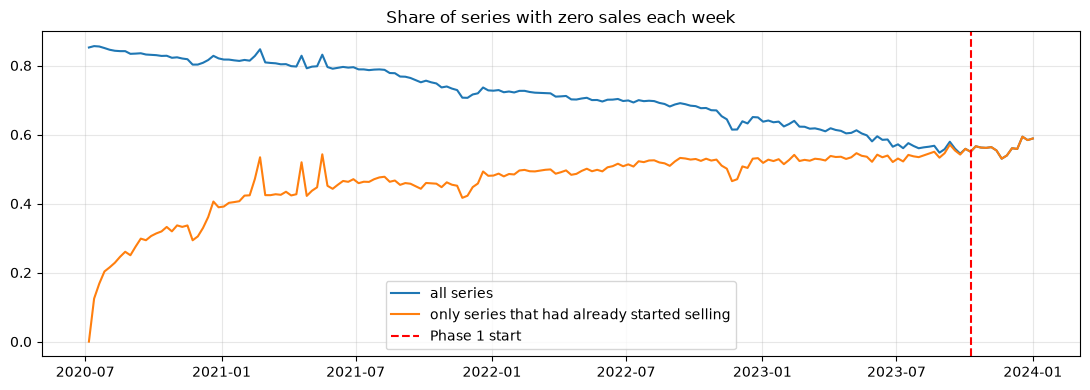

In [21]:
# Q6: activity (run Q5 first: uses vals and first_idx)
o2 = len(sales.columns) - 1                                   # Phase 2 origin = 2024-01-01
for n in [13, 26, 52]:
    dormant = (vals[:, o2 - n + 1 : o2 + 1] == 0).all(axis=1)
    print(f"Sold nothing in the last {n} weeks at the Phase 2 origin: {dormant.sum():,} ({dormant.mean():.1%})")

# How often do quiet series wake up, and how much do they sell when they do?
rows = []
for o in range(60, len(sales.columns) - 13, 4):
    nxt = vals[:, o + 1 : o + 14]
    for n in [13, 26, 52]:
        dormant = (vals[:, o - n + 1 : o + 1] == 0).all(axis=1) & (first_idx <= o)   # started, then went quiet
        if dormant.any():
            rows.append({"quiet for (weeks)": n,
                         "share that sell again in next 13 wks": (nxt[dormant] > 0).any(axis=1).mean(),
                         "share of next-13-wk demand": nxt[dormant].sum() / nxt.sum()})
display(pd.DataFrame(rows).groupby("quiet for (weeks)").mean().map("{:.2%}".format))

# Why did the weekly zero share fall from 71.8% to 56.2%?
alive_all = first_idx[:, None] <= np.arange(vals.shape[1])
plt.figure(figsize=(11, 4))
plt.plot(sales.columns, (vals == 0).mean(axis=0), label="all series")
plt.plot(sales.columns, ((vals == 0) & alive_all).sum(axis=0) / alive_all.sum(axis=0),
         label="only series that had already started selling")
plt.axvline(PHASE1_START, color="red", linestyle="--", label="Phase 1 start")
plt.title("Share of series with zero sales each week")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**What I see:** 

**What it means for Phase 2:** 

## Summary for D014

Which findings support or rule out each Phase 2 candidate (notes/phase2_strategy.md)? Which new
question did this raise?

- 